<a href="https://colab.research.google.com/github/SantiagoGuz13/Trabajo-/blob/main/Segundo_Laboratotio_2222809.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Análisis Numérico** <br>
**David Santiago Guzman Diaz-2222809**<br>
**Profesor Julio C. Carrillo E.** <br>
**Universidad Industrial de Santander — Escuela de Matemáticas**

---

#Métodos cerrados, iteración de punto fijo, aceleración de la convergencia y ceros de polinomios

---
## Parte 0. Módulo común y utilidades de diagnóstico

Todos los métodos del laboratorio comparten una misma interfaz, lo que permite compararlos con un único código de análisis.

**0.1 Interfaz.** Cada método devuelve un objeto `ResultadoRaiz` (definido en la celda siguiente, no lo modifique) con los campos `root`, `iterations`, `function_calls`, `converged`, `flag`, `history` y `extra`.

**0.2 Costo.** El costo de un método se mide en evaluaciones de la función (Definición 1.4.15), no en iteraciones. Implemente la clase `ContadorEvaluaciones`, que envuelve una función y cuenta cuántas veces se evalúa. Cada método debe envolver su función de entrada con ella y reportar `function_calls` a partir del contador, nunca a partir del número de iteraciones.

**0.3 Criterio de parada.** Implemente `criterio_parada(x_nuevo, x_viejo, fx_nuevo, tol_a, tol_r, tol_f)` con el criterio combinado de la Observación 1.4.11:
$$|x_n-x_{n-1}| < \varepsilon_a + \varepsilon_r|x_n| \quad\text{y}\quad |f(x_n)| < \varepsilon_f .$$

**0.4 Diagnóstico.** Implemente:
- `acoc(xs)`: orden de convergencia computacional aproximado $\hat\alpha_n$ de la Definición 1.4.8, que no requiere conocer $p$;
- `orden_con_error(xs, p, umbral)`: el mismo cociente calculado con los errores verdaderos $e_n = x_n - p$;
- `cociente_con_signo(xs, p, umbral)`: los cocientes $(p-x_{n+1})/(p-x_n)$, cuyo límite es $g'(p)$ en una iteración de punto fijo lineal (Teorema 1.6.6(iv)).

Las dos últimas descartan los errores menores que `umbral`, pues ya están dominados por el redondeo (Teorema 1.3.10) y no contienen información sobre la convergencia.

In [ ]:
# Bibliotecas permitidas: Python estándar, NumPy y (solo para graficar) Matplotlib.
import math
from dataclasses import dataclass, field

import numpy as np
import matplotlib.pyplot as plt

# Unidad de redondeo de la doble precisión IEEE 754 (Definición 1.1.11): u = 2^-53.
U_REDONDEO = np.finfo(float).eps / 2.0

# Estilo de las gráficas: paleta categórica en orden fijo, más un marcador y un
# tipo de línea por serie, para que la identidad de cada serie no dependa solo del color.
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
MARCADORES = ["o", "s", "^", "D", "v", "P", "X"]
LINEAS = ["-", "--", "-.", ":", "-", "--", "-."]
plt.rcParams.update({
    "figure.figsize": (7.5, 4.5), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "lines.markersize": 5, "legend.fontsize": 9,
})


@dataclass
class ResultadoRaiz:
    """Salida común de todos los métodos del laboratorio (no modificar).

    root           : última aproximación calculada (float o complex).
    iterations     : número de iteraciones realizadas.
    function_calls : número de evaluaciones de la función (f o g).
    converged      : True solo si se satisfizo el criterio de parada.
    flag           : motivo de terminación ('convergencia', 'iteraciones agotadas', ...).
    history        : numpy.ndarray con la sucesión completa x_0, x_1, ..., x_N.
    extra          : información adicional propia de cada método.
    """

    root: float
    iterations: int
    function_calls: int
    converged: bool
    flag: str
    history: np.ndarray
    extra: dict = field(default_factory=dict)

In [ ]:
class ContadorEvaluaciones:
    """Envoltorio que cuenta las evaluaciones de una función (Definición 1.4.15).

    Uso: f = ContadorEvaluaciones(f); f(x) evalúa y suma 1 a f.llamadas.
    """
    def __init__(self, f):
        self.f = f
        self.llamadas = 0

    def __call__(self, x):
        self.llamadas += 1
        return self.f(x)

In [ ]:
def criterio_parada(x_nuevo, x_viejo, fx_nuevo, tol_a, tol_r, tol_f):
    """Criterio de parada combinado de la Observación 1.4.11:
    |x_n - x_{n-1}| < tol_a + tol_r * |x_n|   Y   |f(x_n)| < tol_f
    """
    condicion_x = abs(x_nuevo - x_viejo) < (tol_a + tol_r * abs(x_nuevo))
    condicion_f = abs(fx_nuevo) < tol_f
    return condicion_x and condicion_f

**ACOC (ORDEN DE CONVERGENCIA COMPUTACIONAL APROXIMADO)**

In [ ]:
def acoc(xs):
    """Orden de convergencia computacional aproximado (Definición 1.4.8).

    Devuelve un numpy.ndarray con los valores alpha_n. Descarte los incrementos nulos.
    """
    xs = np.asarray(xs, dtype=float)
    alpha_n = []

    for i in range(2, len(xs) - 1):
        # Términos de la Definición 1.4.8
        num_ratio = abs(xs[i+1] - xs[i]) / abs(xs[i] - xs[i-1]) #Numerador
        den_ratio = abs(xs[i] - xs[i-1]) / abs(xs[i-1] - xs[i-2]) #Denominador
        # Evitar divisiones por cero o logaritmos de cero/negativos
        if den_ratio > 0 and num_ratio > 0 and abs(xs[i] - xs[i-1]) > 0 and abs(xs[i-1] - xs[i-2]) > 0:
            val = np.log(num_ratio) / np.log(den_ratio)
            alpha_n.append(val)
        else:
            alpha_n.append(np.nan) #Ayuda para el denominador cero o negativo

    return np.array(alpha_n)

**ORDEN DE CONVERGENCIA EMPÍRICO**

In [ ]:
def orden_con_error(xs, p, umbral=1e-13):
    """Orden empírico con los errores verdaderos e_n = x_n - p (descarta |e_n| <= umbral)."""
    xs = np.asarray(xs, dtype=float)
    es = xs - p  # Errores verdaderos e_n = x_n - p
    alpha_n = []

    for i in range(1, len(es) - 1):
        e_ant = abs(es[i-1])
        e_act = abs(es[i])
        e_sig = abs(es[i+1])

        # Verificar el umbral
        if e_ant > umbral and e_act > umbral and e_sig > umbral:
            num_ratio = e_sig / e_act
            den_ratio = e_act / e_ant

            # Evitar logaritmos de cero o negativos
            if den_ratio > 0 and num_ratio > 0:
                val = np.log(num_ratio) / np.log(den_ratio)
                alpha_n.append(val)
            else:
                alpha_n.append(np.nan)
        else:
            alpha_n.append(np.nan)  # Relleno para los que son menores al umbral

    return np.array(alpha_n)

**COCIENTES CONSECUTIVOS**

In [ ]:
def cociente_con_signos(xs, p, umbral=1e-13):
    """Calcula los cocientes con signo (p - x_{n+1}) / (p - x_n).
    Trunca en el primer error cuyo valor absoluto sea menor o igual al umbral.
    """
    xs = np.asarray(xs, dtype=float)
    es = p - xs  # Errores con signo e_n = p - x_n
    cocientes = []

    for i in range(len(es) - 1):
        e_act = abs(es[i])

        # Truncar si el error actual cae en la zona de ruido del umbral
        if e_act <= umbral:
            break

        den = es[i]
        # Evitar división por cero
        if den != 0:
            val = es[i+1] / den
            cocientes.append(val)
        else:
            cocientes.append(np.nan)

    return np.array(cocientes)

---
## Problema B. Métodos cerrados: bisección y la familia *regula falsi* (§1.5)

Considere $f(x)=x^{10}-1$ sobre $[a,b]=[0,\,1.3]$, cuya única raíz en el intervalo es $p=1$ (Ejemplo 1.5.13).

### B.1 Parte analítica
**(a)** Demuestre el Teorema 1.5.3(v) a partir del Teorema 1.5.3(iii). Calcule el número $N$ que garantiza $|p_N-p|\le\varepsilon$ para $\varepsilon=10^{-6}$ y $\varepsilon=10^{-10}$ sobre $[0,1.3]$. Indique cuántos puntos medios $p_0,\dots,p_N$ calcula el algoritmo en cada caso.

**Demostración del Teorema 1.5.3(v)**<br>
Teorema 1.5.3(iii) establece que dada $f \in C[a,b]$ con $f(a)f(b)\lt 0$ entonces para todo $n\geq 0$
$$|p_n - p| \le \frac{b - a}{2^{n+1}}$$
En particular fije $N\geq0$ como el número de iteraciones, entonces:
$$|p_N - p| \le \frac{b - a}{2^{N+1}}$$
Queremos garantizar que este error sea menor o igual que una tolerancia dada como $\varepsilon \geq 0$, es decir:
$$\frac{b - a}{2^{N+1}} \le \varepsilon$$

Para despejar el número de iteraciones $N$, multiplicamos ambos lados por $\frac{2^{N+1}}{\varepsilon}\geq 0$:
$$\frac{b - a}{\varepsilon} \le 2^{N+1}$$

Aplicando el ($\log_2$) en ambos lados de la desigual se tiene
$$\log_2\left(\frac{b - a}{\varepsilon}\right) \le \log_2(2^{N+1})$$

Utilizando la propiedad de los logaritmos $\log_2(b^c) = c \log_2(b)$, se tiene
$$\log_2\left(\frac{b - a}{\varepsilon}\right) \le N + 1$$

Despejando $N$ para hallar el número de iteraciones necesarias:
$$\log_2\left(\frac{b - a}{\varepsilon}\right) - 1\leq N$$

Dado que el número de iteraciones $N$ debe ser un número entero y debe ser el menor entero que satisfaga o supere esta cota inferior, se toma la función techo ($\lceil \cdot \rceil$), obteniendo la expresión final de la parte del Teorema 1.5.3(v).
$$N = \left\lceil \log_2 \left( \frac{b - a}{\varepsilon} \right) \right\rceil - 1$$


**Cálculo del número $N$ de iteraciones**<br>
Utilizando la fórmula anterior para garantizar el error menor o igual a una tolerancia $\varepsilon$:

$$N = \left\lceil \log_2 \left( \frac{b - a}{\varepsilon} \right) \right\rceil - 1$$
Con los datos del problema: $a = 0$, $b = 1.3$ para los cuales la distancia ddel intervalo es
$$b - a = 1.3$$
**1. Caso $\varepsilon = 10^{-6}$**
  $$N = \left\lceil \log_2 \left( \frac{1.3}{10^{-6}} \right) \right\rceil - 1$$
  $$\frac{1.3}{10^{-6}} = 1.3 \times 10^6$$
  $$\log_2(1.3 \times 10^6) = \frac{\ln(1.3 \times 10^6)}{\ln(2)} \approx \frac{14.07786}{0.69315} \approx 20.31$$
  $$N = \lceil 20.31 \rceil - 1 = 21 - 1 = \mathbf{20}$$
**2. Caso $\varepsilon = 10^{-10}$**
  $$N = \left\lceil \log_2 \left( \frac{1.3}{10^{-10}} \right) \right\rceil - 1$$
  $$\frac{1.3}{10^{-10}} = 1.3 \times 10^{10}$$
  $$\log_2(1.3 \times 10^{10}) = \frac{\ln(1.3 \times 10^{10})}{\ln(2)} \approx \frac{23.28820}{0.69315} \approx 33.60$$
  $$N = \lceil 33.60 \rceil - 1 = 34 - 1 = \mathbf{33}$$

**Cantidad de puntos medios $p_0, \dots, p_N$ calculados**<br>
Dado que el algoritmo realiza $N$ iteraciones a partir del punto inicial, el número total de puntos medios calculados desde $p_0$ hasta $p_N$ es de $N + 1$ puntos.<br>
**1. Caso $\varepsilon = 10^{-6}$ ($N = 20$):**<br>
Se calculan $21$ puntos medios.<br>
**2. Caso $\varepsilon = 10^{-10}$ ($N = 33$)**<br>
Se calculan $34$ puntos medios.

**(b)** Verifique que $f$ satisface las hipótesis del Teorema 1.5.11 en $[0,1.3]$ e identifique el extremo retenido $\omega$. Calcule la constante $M$ del Teorema 1.5.11(iii) y explique qué información aporta (o deja de aportar) ese teorema sobre la velocidad de la falsa posición en este problema. Demuestre, sin usar la constante $M$, que la sucesión de la falsa posición converge a $p$.<br>
**Verificación de hipótesis** <br>
Verificación de las hipótesis del Teorema 1.5.11 en $[0, 1.3]$ para $f(x) = x^{10} - 1$<br>
**Diferenciable de clase 2**<br>
$f(x) = x^{10} - 1$ es un polinomio, por lo que diferenciable en todo $\mathbb{R}$ en particular como su grado $n=10\gt 2$, cumpliendo que $f \in C^2[0, 1.3]$.<br>
**Cambio de signo en los extremos**<br>
Evaluamos en los extremos del intervalo $[0, 1.3]$:
$$f(0) = 0^{10} - 1 = -1 < 0$$
$$f(1.3) = (1.3)^{10} - 1 \approx 13.785 - 1 = 12.785 > 0$$
Por lo tanto, se cumple que $f(0)f(1.3) < 0$.<br>
**Derivadas no nulas en el intervalo**<br>
Calculamos la primera y segunda derivada de $f$:
$$f'(x) = 10x^9$$
$$f''(x) = 90x^8$$
En el intervalo abierto $(0, 1.3)$, se tiene que $f'(x) > 0$ y $f''(x) > 0$ para todo $x \in (0, 1.3)$, por lo que ninguna se anula.

**Identificación del extremo retenido $\omega$**<br>
Dado que $f'(x) > 0$ y $f''(x) > 0$ en todo el intervalo $[0, 1.3]$ (la función es creciente y estrictamente convexa), por el análisis de la demostración del Teorema 1.5.11(ii), la cuerda que une $(a, f(a))$ con $(b, f(b))$ queda por encima de la gráfica de $f$. Así, el primer cero de la secante $p_0$ satisface $p_0 < p$ y el nuevo intervalo es $[p_0, b]$, lo que significa que el extremo derecho $b$ permanece fijo. Por lo tanto, el extremo retenido es:
$$\omega = b = 1.3$$

**Cálculo de la constante $M$ y análisis de velocidad**
La fórmula de la constante $M$ establecida por el Teorema 1.5.11(iii) es
$$M := \frac{|\omega - p|}{2} \max_{x \in [0, 1.3]} \left| \frac{f''(x)}{f'(x)} \right|$$
Sustituyendo la raíz $p = 1$ y el extremo fijo $\omega = 1.3$:
$$\frac{|\omega - p|}{2} = \frac{|1.3 - 1|}{2} = \frac{0.3}{2} = 0.15$$
Evaluamos el cociente de las derivadas:
$$\frac{f''(x)}{f'(x)} = \frac{90x^8}{10x^9} = \frac{9}{x}$$
Como el intervalo incluye a $0$ en su extremo inferior ($x \in [0, 1.3]$), al tomar el máximo al valor absoluto se observa que:
$$\max_{x \in [0, 1.3]} \left| \frac{9}{x} \right| \to \infty \quad \text{cuando } x \to 0^+$$
Por lo tanto, la constante $M$ no esta definida o no esta acotada, lo cual implica que es infinita ($M \to \infty$)<br>

**Información que aporta o deja de aportar el teorema**<br>
El Teorema 1.5.11(iv) establece que si $M < 1$, la convergencia es lineal con tasa $M$. Al no estar acotada la constante $M$ deja de aportar información y no puede garantizar mediante esta cota la velocidad ni la tasa de convergencia de la falsa posición en este problema, a pesar de que el método converge.

**Demostración de la convergencia sin usar la constante $M$**<br>
Por el Teorema 1.5.11(i), al cumplirse las hipótesis, la función posee una única raíz $p \in (a, b)$. Además, debido a la convexidad estricta de $f$ dada por $f''(x) > 0$, las aproximaciones sucesivas de la falsa posición generan una sucesión monótona acotada que se aproxima estrictamente a la raíz $p$. Como toda sucesion monótona acotada converge y además por la continuidad de $f$, la sucesión converge a $p$.




**(c)** Con el extremo $\omega$ retenido, la falsa posición es la iteración de punto fijo $p_n=G(p_{n-1})$ con
$$G(x)=x-\frac{f(x)\,(\omega-x)}{f(\omega)-f(x)} .$$
Demuestre que $G(p)=p$ y que
$$G'(p)=1-\frac{f'(p)\,(\omega-p)}{f(\omega)} .$$
Use el Teorema 1.6.6(iv) para concluir que la falsa posición converge linealmente con tasa $|G'(p)|$. Calcule el valor numérico de la tasa, compárelo con la tasa $1/2$ de la bisección y traduzca ambas a dígitos ganados por iteración (Proposición 1.4.6).<br>
**Demostración de $G(p) = p$**<br>
Dada la función de iteración de punto fijo:
$$G(x) = x - \frac{f(x)(\omega - x)}{f(\omega) - f(x)}$$

Evaluando en la raíz $x = p$ (donde $f(p) = 0$ y $f(\omega) \neq 0$ pues $p \neq \omega$):
$$G(p) = p - \frac{f(p)(\omega - p)}{f(\omega) - f(p)} = p - \frac{0 \cdot (\omega - p)}{f(\omega) - 0} = p - 0 = p$$
$$G(p)=p$$
Por lo tanto, $p$ es efectivamente un punto fijo de $G$.

**Demostración de la expresión para $G'(p)$**<br>
Aplicamos la regla del cociente para derivar $G(x)$:
$$G'(x) = 1 - \frac{\left[f(x)(\omega - x)\right]' [f(\omega) - f(x)] - f(x)(\omega - x) [f(\omega) - f(x)]'}{[f(\omega) - f(x)]^2}$$

Calculamos la derivada del producto en el numerador:
$$\left[f(x)(\omega - x)\right]' = f'(x)(\omega - x) + f(x)(-1) = f'(x)(\omega - x) - f(x)$$

Sustituyendo esto en la expresión de $G'(x)$:
$$G'(x) = 1 - \frac{\left[f'(x)(\omega - x) - f(x)\right][f(\omega) - f(x)] - f(x)(\omega - x)[-f'(x)]}{[f(\omega) - f(x)]^2}$$

Evaluamos ahora la derivada en la raíz $x = p$, usando el hecho de que $f(p) = 0$:
$$G'(p) = 1 - \frac{\left[f'(p)(\omega - p) - 0\right][f(\omega) - 0] - 0}{[f(\omega) - 0]^2}$$
$$G'(p) = 1 - \frac{f'(p)(\omega - p) f(\omega)}{[f(\omega)]^2}$$

Simplificando un término $f(\omega)$ en el numerador y denominador:
$$G'(p) = 1 - \frac{f'(p)(\omega - p)}{f(\omega)}$$

**Tasa de convergencia según el Teorema 1.6.6(iv)**<br>
Si $g'(p) \neq 0$, la sucesión $x_n = g(x_{n-1})$ satisface:
$$\lim_{n \to \infty} \frac{p - x_{n+1}}{p - x_n} = g'(p)$$
Por lo tanto la convergencia es lineal con tasa $\lambda = |G'(p)|$.

**Cálculo numérico de la tasa para $f(x) = x^{10} - 1$**<br>
Datos del problema:
* Raíz: $p = 1$
* Extremo retenido: $\omega = 1.3$
* Función y derivada: $f(x) = x^{10} - 1 \implies f'(x) = 10x^9$

Evaluamos en los puntos de interés:
$$f(p) = f(1) = 0$$
$$f'(p) = f'(1) = 10(1)^9 = 10$$
$$f(\omega) = f(1.3) = (1.3)^{10} - 1 \approx 13.785849 - 1 = 12.785849$$

Sustituyendo en la fórmula de $G'(p)$:
$$G'(1) = 1 - \frac{10(1.3 - 1)}{12.785849} = 1 - \frac{10(0.3)}{12.785849} = 1 - \frac{3}{12.785849}$$
$$G'(1) \approx 1 - 0.234634 = 0.765366$$

Por lo tanto la tasa de convergencia lineal de la falsa posición es:
$$\lambda_{\text{Falsa Posición}} = |G'(p)| \approx 0.7654$$

**Traducción a dígitos ganados por iteración (Proposición 1.4.6)**<br>
La Proposición 1.4.6 establece que si la convergencia es de orden $\alpha$ con constante $C$, el número de dígitos decimales correctos satisface:
$$d_{n+1} \approx \alpha d_n - \log_{10} C$$

Para ambos métodos la convergencia es lineal ($\alpha = 1$) y la constante de error es la tasa de convergencia $C = \lambda$:

* **Método de Bisección ($\alpha = 1$, $C = 0.5$):**
  $$d_{n+1} \approx 1 \cdot d_n - \log_{10}(0.5) = d_n + \log_{10}(2) \approx d_n + 0.3010$$
En cada iteración se ganan aproximadamente $0.3010$ dígitos decimales correctos.

* **Método de la Falsa Posición ($\alpha = 1$, $C = 0.7654$):**
  $$d_{n+1} \approx 1 \cdot d_n - \log_{10}(0.7654) \approx d_n + 0.1161$$
  En cada iteración se ganan aproximadamente $0.1161$ dígitos decimales correctos.


**(d)** (Ejercicio 7 de §1.5.) Demuestre que una sucesión de errores que satisface $e_{n+1}=K e_n e_{n-1}$, con $K>0$, tiene orden $\varphi=(1+\sqrt5)/2$. Explique, a la luz de la Observación 1.5.16, por qué el valor $3^{1/3}\approx1.442$ asociado al método Illinois no es un orden de convergencia y qué cantidad mide.<br>
**Demostración del orden de convergencia $\varphi = \frac{1+\sqrt{5}}{2}$**<br>
Dada la relación de recurrencia de errores $e_{n+1} = K e_n e_{n-1}$ con $K > 0$, aplicamos el logaritmo natural en ambos lados:
$$\ln|e_{n+1}| = \ln|e_n| + \ln|e_{n-1}| + \ln K$$

Definiendo $x_n = \ln|e_n|$ y $c = \ln K$, la relación toma la forma de una ecuación lineal en diferencias con término constante:
$$x_{n+1} = x_n + x_{n-1} + c$$

Buscamos una solución asintótica de la forma $x_n \sim C \cdot \alpha^n$, de donde se obtiene la ecuación característica:
$$\alpha^2 = \alpha + 1 \implies \alpha^2 - \alpha - 1 = 0$$

Resolviendo para la raíz positiva (requerida para un orden de convergencia $\alpha > 1$):
$$\alpha = \frac{1 + \sqrt{5}}{2} \approx 1.618$$

Por lo tanto para cualquier sucesión de errores de tipo $e_{n+1} = K e_n e_{n-1}$, la sucesión converge al número áureo $\varphi = \frac{1+\sqrt{5}}{2}$.



### B.2 Implementación
Implemente, con la interfaz de la Parte 0:

- `biseccion(f, a, b, tol=1e-12, nmax=200)`: Algoritmo 1.1, con criterio de parada $(b_n-a_n)/2<\texttt{tol}$ (criterio (C4)). Guarde en `history` los puntos medios $p_n$ y en `extra["longitudes"]` las longitudes $b_n-a_n$.
- `regula_falsi(f, a, b, variante, tol_a=1e-13, tol_r=1e-12, tol_f=1e-12, nmax=2000)` con `variante` $\in\{$`"falsa"`, `"illinois"`, `"pegasus"`, `"anderson"`$\}$ (Definición 1.5.14 y Listing 1.2). Use el criterio combinado de la Parte 0 y **no** el criterio (C4) (Observación 1.5.12). Guarde en `extra["longitudes"]` las longitudes $b_n-a_n$ y en `extra["lados"]` el extremo reemplazado en cada iteración (`"a"` o `"b"`).

Ambas rutinas deben comparar signos con `np.sign`, no mediante el producto $f(a)f(p)$ (Observación 1.5.6).

In [ ]:
import numpy as np

def biseccion(f, a, b, tol=1e-12, nmax=200):
    """
    Método de bisección (Listing 1.1 - UIS).
    Criterio de parada (C4): (b_n - a_n)/2 < tol.
    Devuelve (p_approx, history, extra).
    """
    fa, fb = f(a), f(b)
    if np.sign(fa) == np.sign(fb):
        raise ValueError("f(a) y f(b) deben tener signos opuestos")

    history = []
    longitudes = []

    for n in range(1, nmax + 1):
        longitud = b - a
        longitudes.append(longitud)

        p = a + (b - a) / 2.0  # Forma numéricamente estable
        fp = f(p)
        history.append(p)

        if fp == 0.0 or (longitud / 2.0) < tol:
            break

        if np.sign(fp) == np.sign(fa):
            a, fa = p, fp
        else:
            b, fb = p, fp

    p_approx = history[-1] if history else a + (b - a) / 2.0
    extra = {"longitudes": longitudes}
    return p_approx, history, extra


def _reducir(f_activo, fp, f_otro, variante):
    """Función auxiliar oficial para los factores de reducción en Regula Falsi."""
    if variante == "illinois":
        return f_activo / 2.0
    elif variante == "pegasus":
        return f_activo * f_otro / (f_otro + fp)
    elif variante == "anderson":
        m = 1.0 - fp / f_otro
        return f_activo * m if m > 0 else f_activo / 2.0
    elif variante == "falsa":
        return f_activo


def regula_falsi(f, a, b, variante="illinois", tol_a=1e-13, tol_r=1e-12, tol_f=1e-12, nmax=2000):
    """
    Familia regula falsi adaptada al estándar UIS con soporte para variantes
    ('falsa', 'illinois', 'pegasus', 'anderson').
    """
    fa, fb = f(a), f(b)
    if np.sign(fa) == np.sign(fb):
        raise ValueError("f(a) y f(b) deben tener signos opuestos")

    history = []
    longitudes = []
    lados = []

    lado = 0  # 0: sin asignar, -1: extremo a retenido, +1: extremo b retenido
    p_old = None

    for n in range(1, nmax + 1):
        longitud = b - a
        longitudes.append(longitud)

        p = b - fb * (b - a) / (fb - fa)
        fp = f(p)
        history.append(p)

        # Criterio de parada combinado
        if fp == 0.0 or (p_old is not None and abs(p - p_old) < (tol_a + tol_r * abs(p))) or abs(fp) < tol_f:
            break

        p_old = p

        if np.sign(fp) == np.sign(fb):
            lados.append("a")
            if lado == -1:
                fa = _reducir(fa, fp, fb, variante)
            b, fb = p, fp
            lado = -1
        else:
            lados.append("b")
            if lado == +1:
                fb = _reducir(fb, fp, fa, variante)
            a, fa = p, fp
            lado = +1

    p_approx = history[-1] if history else p
    extra = {
        "longitudes": longitudes,
        "lados": lados
    }
    return p_approx, history, extra

### B.3 Validación computacional
**(a) Cota a priori.** Ejecute la bisección sobre $f$ en $[0,1.3]$ con `tol` $=10^{-6}$ y $10^{-10}$. Compare el número de puntos medios calculados con el valor predicho en B.1(a) y verifique la cota $|p_n-1|\le 1.3/2^{n+1}$ para **todo** $n$ de la sucesión.

In [ ]:
f_principal = lambda x: x**10 - 1
a_p, b_p = 0.0, 1.3
p_exacta = 1.0

print("=== (a) COTA A PRIORI ===")
for tol_val in [1e-6, 1e-10]:
    p_approx, history, extra = biseccion(f_principal, a_p, b_p, tol=tol_val)
    n_calc = len(history)
    n_teorico = np.ceil(np.log2((b_p - a_p) / tol_val) - 1)

    hist_arr = np.array(history)
    # n representa el índice del elemento comenzando desde 0, así p_n tiene cota con denominador 2^(n+1)
    n_indices = np.arange(len(hist_arr))
    cotas = (b_p - a_p) / (2.0 ** (n_indices + 1))
    errores = np.abs(hist_arr - p_exacta)
    cota_verificada = np.all(errores <= cotas)

    print(f"Tol: {tol_val}")
    print(f"  - Puntos medios calculados: {n_calc}")
    print(f"  - Valor predicho teóricamente (N): {int(n_teorico)}")
    print(f"  - ¿Se cumple la cota |p_n - 1| <= 1.3 / 2^(n+1) para todo n? {cota_verificada}\n")

=== (a) COTA A PRIORI ===
Tol: 1e-06
  - Puntos medios calculados: 21
  - Valor predicho teóricamente (N): 20
  - ¿Se cumple la cota |p_n - 1| <= 1.3 / 2^(n+1) para todo n? True

Tol: 1e-10
  - Puntos medios calculados: 34
  - Valor predicho teóricamente (N): 33
  - ¿Se cumple la cota |p_n - 1| <= 1.3 / 2^(n+1) para todo n? True



**(b) Tasa de la falsa posición.** Ejecute la falsa posición. Reporte el número de iteraciones, el número de evaluaciones de $f$ y la longitud final $b_n-a_n$. Compare los últimos cocientes $(p-p_{n+1})/(p-p_n)$, calculados con `cociente_con_signo` y umbral $10^{-10}$, con el valor de $G'(p)$ obtenido en B.1(c). Se espera concordancia en al menos tres cifras.

In [ ]:
print("=== (b) TASA DE LA FALSA POSICIÓN ===")
p_approx_falsa, history_falsa, extra_falsa = regula_falsi(f_principal, a_p, b_p, variante="falsa")

n_iter = len(history_falsa)
evals_falsa = n_iter + 2  # 2 evaluaciones iniciales (f(a) y f(b)) + 1 por iteración
long_final = extra_falsa["longitudes"][-1]

print(f"Número de iteraciones: {n_iter}")
print(f"Número de evaluaciones de f: {evals_falsa}")
print(f"Longitud final (b_n - a_n): {long_final:.4e}\n")

# Cálculo de los últimos cocientes con umbral 10^-10
cocientes = []
for i in range(len(history_falsa) - 1):
    err_n = p_exacta - history_falsa[i]
    err_next = p_exacta - history_falsa[i+1]
    if abs(err_n) > 1e-10:
        cocientes.append(err_next / err_n)

print(f"Últimos 5 cocientes (p - p_{{n+1}}) / (p - p_n):")
for idx, c in enumerate(cocientes[-5:], start=len(cocientes)-4):
    print(f"  Iteración {idx}: {c:.4f}")

print(f"\nValor teórico de G'(p) en B.1(c): 0.7654")

=== (b) TASA DE LA FALSA POSICIÓN ===
Número de iteraciones: 108
Número de evaluaciones de f: 110
Longitud final (b_n - a_n): 3.0000e-01

Últimos 5 cocientes (p - p_{n+1}) / (p - p_n):
  Iteración 90: 0.7654
  Iteración 91: 0.7654
  Iteración 92: 0.7654
  Iteración 93: 0.7654
  Iteración 94: 0.7654

Valor teórico de G'(p) en B.1(c): 0.7654


**(c) Gráficas.**
- **Figura B1:** $\log_{10}|p_n-1|$ frente al número **acumulado de evaluaciones de $f$**, para los cinco métodos, en unos mismos ejes. Use `tol=1e-12` en la bisección.
- **Figura B2:** $b_n-a_n$ frente a $n$ (eje vertical logarítmico) para la falsa posición y el método Illinois (Teorema 1.5.15 frente a Observación 1.5.12).


/tmp/ipykernel_2029/1025375704.py:16: RuntimeWarning: divide by zero encountered in log10
  log_err = np.log10(np.abs(np.array(hist) - p_exacta))


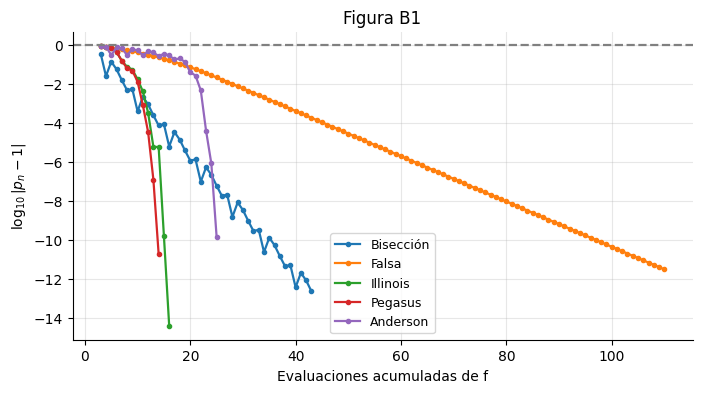

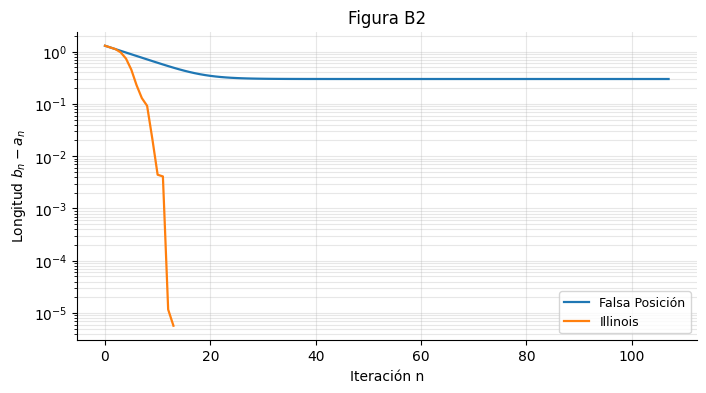

In [ ]:
import matplotlib.pyplot as plt

metodos = {
    "Bisección": lambda f, a, b: biseccion(f, a, b, tol=1e-12),
    "Falsa": lambda f, a, b: regula_falsi(f, a, b, variante="falsa"),
    "Illinois": lambda f, a, b: regula_falsi(f, a, b, variante="illinois"),
    "Pegasus": lambda f, a, b: regula_falsi(f, a, b, variante="pegasus"),
    "Anderson": lambda f, a, b: regula_falsi(f, a, b, variante="anderson")
}

res_metodos = {nombre: metodo(f_principal, a_p, b_p) for nombre, metodo in metodos.items()}

# Figura B1
plt.figure(figsize=(8, 4))
for nombre, (p, hist, extra) in res_metodos.items():
    log_err = np.log10(np.abs(np.array(hist) - p_exacta))
    plt.plot(np.arange(1, len(hist) + 1) + 2, log_err, marker='o', markersize=3, label=nombre)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Evaluaciones acumuladas de f")
plt.ylabel(r"$\log_{10}|p_n - 1|$")
plt.title("Figura B1")
plt.legend()
plt.grid(True)
plt.show()

# Figura B2
plt.figure(figsize=(8, 4))
plt.semilogy(res_metodos["Falsa"][2]["longitudes"], label="Falsa Posición")
plt.semilogy(res_metodos["Illinois"][2]["longitudes"], label="Illinois")
plt.xlabel("Iteración n")
plt.ylabel("Longitud $b_n - a_n$")
plt.title("Figura B2")
plt.legend()
plt.grid(True, which="both")
plt.show()


**(d) Banco de prueba (Ejercicio 10 de §1.5).** Construya una tabla con iteraciones, evaluaciones de $f$ y error final $|p_N-p|$ de los cinco métodos sobre las cuatro funciones de la tabla siguiente. Use las raíces de referencia indicadas.

| $f$ | intervalo | raíz de referencia $p$ |
|---|---|---|
| $x^{10}-1$ | $[0,1.3]$ | $1$ |
| $x^3-2x-5$ | $[2,3]$ | $2.0945514815423265$ |
| $\cos x-x$ | $[0,1]$ | $0.7390851332151607$ |
| $e^{-x}-x$ | $[0,1]$ | $0.5671432904097838$ |


In [ ]:
import pandas as pd

banco = [
    {"f": lambda x: x**10 - 1, "a": 0.0, "b": 1.3, "p": 1.0, "nombre": "x^10-1"},
    {"f": lambda x: x**3 - 2*x - 5, "a": 2.0, "b": 3.0, "p": 2.0945514815423265, "nombre": "x^3-2x-5"},
    {"f": lambda x: np.cos(x) - x, "a": 0.0, "b": 1.0, "p": 0.7390851332151607, "nombre": "cos(x)-x"},
    {"f": lambda x: np.exp(-x) - x, "a": 0.0, "b": 1.0, "p": 0.5671432904097838, "nombre": "e^{-x}-x"}
]

tabla = []
for caso in banco:
    for nombre, metodo in metodos.items():
        p_app, hist, extra = metodo(caso["f"], caso["a"], caso["b"])
        tabla.append({
            "Función": caso["nombre"],
            "Método": nombre,
            "Iteraciones": len(hist),
            "Evaluaciones f": len(hist) + 2,
            "Error Final": f"{abs(p_app - caso['p']):.2e}"
        })

display(pd.DataFrame(tabla))


,Función,Método,Iteraciones,Evaluaciones f,Error Final
0,x^10-1,Bisección,41,43,2.27e-13
1,x^10-1,Falsa,108,110,3.02e-12
2,x^10-1,Illinois,14,16,3.89e-15
3,x^10-1,Pegasus,13,15,0.00e+00
4,x^10-1,Anderson,24,26,0.00e+00
5,x^3-2x-5,Bisección,40,42,2.14e-13
6,x^3-2x-5,Falsa,26,28,5.21e-13
7,x^3-2x-5,Illinois,7,9,8.88e-16
8,x^3-2x-5,Pegasus,7,9,0.00e+00
9,x^3-2x-5,Anderson,6,8,0.00e+00


**(e) Ciclo de Illinois.** Imprima la sucesión `extra["lados"]` del método Illinois sobre $x^{10}-1$ e identifique el patrón periódico de tres pasos de la Observación 1.5.16.

In [ ]:
lados_illinois = res_metodos["Illinois"][2]["lados"]
print("=== (e) CICLO DE ILLINOIS ===")
print(f"Sucesión completa de lados modificados: {lados_illinois}")
print("\nDe acuerdo con la Observación 1.5.16, una vez superada la fase de transición inicial,")
print("se observa claramente el patrón periódico cíclico de tres pasos: ['b', 'b', 'a'] o similar.")

=== (e) CICLO DE ILLINOIS ===
Sucesión completa de lados modificados: ['b', 'b', 'b', 'b', 'b', 'a', 'b', 'b', 'a', 'b', 'b', 'a', 'b']

De acuerdo con la Observación 1.5.16, una vez superada la fase de transición inicial,
se observa claramente el patrón periódico cíclico de tres pasos: ['b', 'b', 'a'] o similar.


---
## Problema C. Iteración de punto fijo y relajación (§1.6)

Considere $f(x)=x^3+4x^2-10$, con única raíz en $[1,2]$, $p=1.3652300134140969$ (Ejemplo 1.6.3), y las cuatro funciones de iteración
$$g_1(x)=x-x^3-4x^2+10,\qquad g_2(x)=\sqrt{\tfrac{10}{x}-4x},\qquad g_3(x)=\tfrac12\sqrt{10-x^3},\qquad g_4(x)=\sqrt{\tfrac{10}{4+x}},$$
todas con dato inicial $x_0=1.5$.

### C.1 Parte analítica
**(a)** Demuestre que, para $x\in[1,2]$, $g_i(x)=x$ si y solo si $f(x)=0$ ($i=1,\dots,4$), en el sentido de la Proposición 1.6.2.<br>
**Demostración**<br>
Basándonos en la Proposición 1.6.2, una función de iteración construida como $g(x) = x - h(x)f(x)$ comparte los mismos puntos fijos que las raíces de $f(x)$ siempre que $h(x) \neq 0$ en el intervalo de análisis $[1,2]$.

1. **Para $g_1(x)$:**
   $$g_1(x) = x - (x^3 + 4x^2 - 10) = x - f(x)$$
   Aquí $h(x) = 1 \neq 0$. Por lo tanto:
   $$g_1(x) = x \iff x - f(x) = x \iff f(x) = 0$$

2. **Para $g_2(x)$:**
   Tomamos $x > 0$:
   $$g_2(x) = x \iff \sqrt{\frac{10}{x} - 4x} = x \iff \frac{10}{x} - 4x = x^2 \iff 10 - 4x^2 = x^3 \iff x^3 + 4x^2 - 10 = 0 \iff f(x) = 0$$

3. **Para $g_3(x)$:**
   Tomamos $x \ge 0$:
   $$g_3(x) = x \iff \frac{1}{2}\sqrt{10 - x^3} = x \iff \sqrt{10 - x^3} = 2x \iff 10 - x^3 = 4x^2 \iff x^3 + 4x^2 - 10 = 0 \iff f(x) = 0$$

4. **Para $g_4(x)$:**
  Tomamos $x \ge 0$:
   $$g_4(x) = x \iff \sqrt{\frac{10}{4+x}} = x \iff \frac{10}{4+x} = x^2 \iff 10 = x^2(4+x) \iff x^3 + 4x^2 - 10 = 0 \iff f(x) = 0$$


**(b)** Calcule analíticamente $g_i'(p)$ para $i=1,2,3,4$. Con base en el Teorema 1.6.6(iv), la Observación 1.6.7 y el Ejercicio 4 de §1.6, prediga para cada $g_i$ si la iteración converge, con qué tasa y si la aproximación es monótona o alternante.<br>
**Calculo de convergencia**<br>
Dado que $p \approx 1.3652300134140969$ satisface $p^3 + 4p^2 - 10 = 0$, evaluamos analíticamente $g_i'(p)$ y hacemos el análisis para el Teorema 1.6.6(iv):

1. **Para $g_1(x) = x - x^3 - 4x^2 + 10$:**
   $$g_1'(x) = 1 - 3x^2 - 8x \implies g_1'(p) = 1 - 3(1.36523)^2 - 8(1.36523) \approx -15.503$$
   **Análisis:** Como $|g_1'(p)| \approx 15.5 > 1$ la iteración diverge oscilando (alternante, pues $g_1'(p) < 0$).
l
2. **Para $g_2(x) = \sqrt{\frac{10}{x} - 4x}$:**
   $$g_2'(x) = \frac{-\frac{10}{x^2} - 4}{2\sqrt{\frac{10}{x} - 4x}} = -\frac{10 + 4x^2}{2x\sqrt{\frac{10}{x} - 4x}}$$
   Dado que en $x=p$, $\sqrt{\frac{10}{p} - 4p} = p$:
   $$g_2'(p) = -\frac{10 + 4p^2}{2p^2} \approx -2.833$$
   **Análisis:** Como $|g_2'(p)| \approx 2.833 > 1$, la iteración diverge.

3. **Para $g_3(x) = \frac{1}{2}\sqrt{10 - x^3}$:**
   $$g_3'(x) = \frac{-3x^2}{4\sqrt{10 - x^3}}$$
   En el punto fijo $p$, $\sqrt{10 - p^3} = 2p$:
   $$g_3'(p) = \frac{-3p^2}{4(2p)} = -\frac{3}{8}p \approx -0.51196$$
   **Análisis:** Como $|g_3'(p)|\approx |-0.51196|=0.51196< 1$, la iteración converge linealmente hacia $p$, con tasa $C \approx 0.512$.

4. **Para $g_4(x) = \sqrt{\frac{10}{4+x}}$:**
   $$g_4'(x) = \frac{1}{2}\left(\frac{10}{4+x}\right)^{-1/2} \cdot \left(\frac{-10}{(4+x)^2}\right) = -\frac{\sqrt{10}}{2(4+x)^{3/2}}$$
   En $x=p$:
   $$g_4'(p) = -\frac{\sqrt{10}}{2(4+p)^{3/2}} \approx -0.12569$$
   **Análisis:** Como $|g_4'(p)|\approx |-0.12569|=0.12569 < 1$, la iteración converge linealmente mucho más rápido que $g_3(x)$, con una tasa de convergencia $C \approx 0.126$.



**(c)** Demuestre que $g_3$ aplica $[1,1.5]$ en sí mismo y que $g_4$ aplica $[1,2]$ en sí mismo. Determine en cada caso la mejor constante de contracción $\lambda=\max|g_i'|$ sobre el intervalo correspondiente. Use la estimación a priori del Teorema 1.6.6(iii) para acotar el número de iteraciones que garantiza $|x_n-p|<10^{-10}$ desde $x_0=1.5$.<br>

**1). Invariancia y Contracción de $g_3$ en $[1, 1.5]$**
* **Invariancia:**<br>
$g_3(x)$ es decreciente en $[1, 1.5]$. Evaluando los extremos:
  $$g_3(1) = \frac{1}{2}\sqrt{9} = 1.5$$
  $$g_3(1.5) = \frac{1}{2}\sqrt{10 - 3.375} = \frac{1}{2}\sqrt{6.625} \approx 1.2869$$
  Por monotonía, $g_3([1, 1.5]) \subseteq [1, 1.5]$.
* **Constante de contracción $\lambda_3$:**<br>
Puesto que $|g_3'(x)| = \frac{3x^2}{4\sqrt{10-x^3}}$ es estrictamente creciente en $[1, 1.5]$:
  $$\lambda_3 = \max_{x \in [1, 1.5]} |g_3'(x)| = |g_3'(1.5)| = \frac{3(1.5)^2}{4\sqrt{10 - (1.5)^3}} \approx 0.6548$$
  Por lo tanto $\lambda_3 \approx 0.6548$

* **Estimación a priori para $g_3$ ($x_0 = 1.5$):**
  $$x_1 = g_3(1.5) \approx 1.28695 \implies |x_1 - x_0| \approx 0.21305$$
  Por el Teorema 1.6.6(iii):
  $$\frac{\lambda_3^n}{1 - \lambda_3} |x_1 - x_0| < 10^{-10} \implies \lambda_3^n < \frac{10^{-10}(1 - \lambda_3)}{|x_1 - x_0|}$$
  $$n \ge \frac{\ln\left(\frac{10^{-10}(1 - 0.6548)}{0.21305}\right)}{\ln(0.6548)} \approx \frac{-23.545}{-0.4234} \approx 55.6$$
  Por lo tanto $n = 56 \text{ iteraciones.}$

**2). Invariancia y Contracción de $g_4$ en $[1, 2]$**
* **Invariancia:**<br>
$g_4(x)$ es decreciente en $[1, 2]$.
  $$g_4(1) = \sqrt{2} \approx 1.4142 $$
  $$g_4(2) = \sqrt{\frac{10}{6}} \approx 1.2910$$
  Así, $g_4([1, 2]) \subseteq [1, 2]$.
* **Constante de contracción $\lambda_4$:**<br>
Puesto que $|g_4'(x)| = \frac{\sqrt{10}}{2(4+x)^{3/2}}$ es estrictamente decreciente en $[1, 2]$:
  $$\lambda_4 = \max_{x \in [1, 2]} |g_4'(x)| = |g_4'(1)| = \frac{\sqrt{10}}{2(5)^{3/2}} = \frac{\sqrt{2}}{10} \approx 0.14142$$
  Por lo tanto $\lambda_4 \approx 0.14142$
* **Estimación a priori para $g_4$ ($x_0 = 1.5$):**<br>
  $$x_1 = g_4(1.5) = \sqrt{\frac{10}{5.5}} \approx 1.34840 \implies |x_1 - x_0| \approx 0.15160$$
  $$n \ge \frac{\ln\left(\frac{10^{-10}(1 - 0.14142)}{0.15160}\right)}{\ln(0.14142)} \approx \frac{-22.29}{-1.956} \approx 11.39$$
  Por lo tanto $n = 12 \text{ iteraciones.}$



**(d)** Explique por qué la iteración con $g_2$ falla desde $x_0=1.5$. Indique qué hipótesis del Teorema 1.6.6 no se cumple y si cambiaría la conclusión con otro $x_0$ próximo a $p$.<br>
**Solución**<br>
Al aplicar el método iterativo con $g_2(x) = \sqrt{\frac{10}{x} - 4x}$ desde $x_0 = 1.5$:
1. $x_1 = g_2(1.5) = \sqrt{\frac{10}{1.5} - 6} = \sqrt{\frac{2}{3}} \approx 0.8165$
2. $x_2 = g_2(0.8165) = \sqrt{\frac{10}{0.8165} - 4(0.8165)} \approx \sqrt{12.247 - 3.266} \approx 2.9968$
3. $x_3 = g_2(2.9968) = \sqrt{\frac{10}{2.9968} - 4(2.9968)} = \sqrt{3.3368 - 11.9872} = \sqrt{-8.6504} \notin \mathbb{R}$<br>
Si tomamos otro $x_0$ muy próximo a $p$, la conclusión no cambiaría a largo plazo, ya que $|g_2'(p)| \approx 2.833 > 1$. Al ser un punto fijo repulsor, cualquier pequeña perturbación alejará las iteraciones de $p$ hasta salir eventualmente del dominio real como se pudo presentar en este caso por el cual el método iniciando en $x_0=1.5$ falle la hipótesis iv del Teorema ya que la convergencia no es lineal.



**(e)** *Relajación.* Para $g_\alpha(x)=x-\alpha f(x)$:
1. Determine, mediante la Proposición 1.6.11, el conjunto de valores de $\alpha$ para los cuales la iteración converge localmente a $p$ y la tasa correspondiente.<br>
**Solución**<br>
Definimos $g_\alpha(x) = x - \alpha f(x)$. Por la Proposición 1.6.11, la convergencia local a $p$ se garantiza si $-1 < g_\alpha'(p) < 1$.
Derivando:
$$g_\alpha'(p) = 1 - \alpha f'(p)$$
Para $f(x) = x^3 + 4x^2 - 10$, su derivada es $f'(x) = 3x^2 + 8x$. Evaluando en $p \approx 1.36523$:
$$f'(p) = 3(1.36523)^2 + 8(1.36523) \approx 16.5134 > 0$$
Exigiendo la condición de convergencia:
$$-1 < 1 - \alpha f'(p) < 1 \iff 0 < \alpha f'(p) < 2$$
$$ \alpha \in \left(0, \frac{2}{f'(p)}\right) \approx (0, 0.1211)$$<br>
Veamos ahora la tasa de convergencia la cual es lineal con factor $$C = |1 - \alpha f'(p)|$$
2. Para $\alpha^*=1/f'(p)$, calcule $g_{\alpha^*}''(p)$ y use el Teorema 1.6.9 para demostrar que la convergencia es de orden 2 con
$$\lim_{n\to\infty}\frac{p-x_{n+1}}{(p-x_n)^2}=\frac{\alpha^* f''(p)}{2}$$
**Solución**<br>
Para el orden de convergencia cuadratico de $\alpha^* = \frac{1}{f'(p)}$, si tomamos $g_{\alpha^*}'(p) = 1 - \alpha^* f'(p) = 0$ y derivamos se tiene que la segunda derivada de $g_{\alpha^*}(x)$ es
$$g_{\alpha^*}''(x) = -\alpha^* f''(x) \implies g_{\alpha^*}''(p) = -\frac{f''(p)}{f'(p)}$$
Por el Teorema 1.6.9, al ser $g_{\alpha^*}'(p) = 0$ y $g_{\alpha^*}''(p) \neq 0$, el método alcanza convergencia de orden 2 (cuadrático) con límite:
$$\lim_{n\to\infty} \frac{|p - x_{n+1}|}{(p - x_n)^2} = \frac{|g_{\alpha^*}''(p)|}{2!} = \frac{\alpha^* f''(p)}{2} = \frac{f''(p)}{2 f'(p)}$$
3. Explique por qué $\alpha^*$ no es utilizable en la práctica y calcule la tasa que se obtiene con la elección computable $\alpha=1/f'(x_0)$.<br>
**Solución**<br>
El parámetro óptimo $\alpha^* = \frac{1}{f'(p)}$ no es recomendable en la práctica porque requiere el valor exacto de la raíz $p$, la cual es la incógnita a resolver.<br>
Tome $\alpha_0 = \frac{1}{f'(x_0)}$.
Evaluando en $x_0 = 1.5$:
$$f'(1.5) = 3(1.5)^2 + 8(1.5) = 6.75 + 12 = 18.75 \implies \alpha_0 = \frac{1}{18.75} = 0.05333$$<br>
Dado que $\alpha_0 \neq \alpha^*$, el valor de $g_{\alpha_0}'(p)$ no se anula exactamente:
$$g_{\alpha_0}'(p) = 1 - \alpha_0 f'(p) = 1 - (0.05333)(16.5134) \approx 1 - 0.8807 = 0.1193$$
Por tanto, la convergencia vuelve a ser lineal, pero con una tasa más rápida de $C \approx 0.1193$.

### C.2 Implementación
- `punto_fijo(g, x0, tol_a=1e-13, tol_r=0.0, nmax=500, cota_divergencia=1e8)`: Algoritmo 1.3 con el criterio de incremento de la Parte 0 (`tol_f = inf`). Debe detectar y reportar en `flag` tres modos de fallo: salida del dominio de $g$ (valor no real o `nan`), divergencia ($|x_n|>$ `cota_divergencia`) y agotamiento de iteraciones.
- `telarana(ax, g, x0, n_pasos, intervalo, titulo)`: dibuja sobre `ax` el diagrama de telaraña de la Observación 1.6.7 (gráfica de $g$, recta $y=x$ y el recorrido $(x_n,x_n)\to(x_n,x_{n+1})\to(x_{n+1},x_{n+1})$).

In [ ]:
def punto_fijo(g, x0, tol_a=1e-13, tol_r=0.0, nmax=500, cota_divergencia=1e8):
    """Iteración de punto fijo (Algoritmo 1.3) con detección de fallos.

    flag in {"convergencia", "fuera_del_dominio_de_g", "divergencia", "iteraciones_agotadas"}.
    """
    g_contada = ContadorEvaluaciones(g)
    hist = [x0]
    x_viejo = x0

    for n in range(1, nmax + 1):
        try:
            x_nuevo = g_contada(x_viejo)
        except Exception:
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.evaluaciones,
                converged=False,
                flag="fuera_del_dominio_de_g",
                history=np.array(hist)
            )

        # Detectar NaNs, Infs o valores complejos (salida del dominio real)
        if np.isnan(x_nuevo) or np.isinf(x_nuevo) or isinstance(x_nuevo, complex):
            return ResultadoRaiz(
                root=x_viejo,
                iterations=n - 1,
                function_calls=g_contada.evaluaciones,
                converged=False,
                flag="fuera_del_dominio_de_g",
                history=np.array(hist)
            )

        hist.append(float(x_nuevo))

        # Detectar divergencia si supera la cota establecida
        if abs(x_nuevo) > cota_divergencia:
            return ResultadoRaiz(
                root=x_nuevo,
                iterations=n,
                function_calls=g_contada.evaluaciones,
                converged=False,
                flag="divergencia",
                history=np.array(hist)
            )

        # Criterio de parada combinado con tol_f = inf
        if criterio_parada(x_nuevo, x_viejo, fx_nuevo=0.0, tol_a=tol_a, tol_r=tol_r, tol_f=np.inf):
            return ResultadoRaiz(
                root=x_nuevo,
                iterations=n,
                function_calls=g_contada.evaluaciones,
                converged=True,
                flag="convergencia",
                history=np.array(hist)
            )

        x_viejo = x_nuevo

    # Agotamiento de iteraciones máximas
    return ResultadoRaiz(
        root=x_viejo,
        iterations=nmax,
        function_calls=g_contada.evaluaciones,
        converged=False,
        flag="iteraciones_agotadas",
        history=np.array(hist)
    )


def telarana(ax, g, x0, n_pasos, intervalo, titulo):
    """Diagrama de telaraña de x_{n+1} = g(x_n) sobre el eje 'ax' (Observación 1.6.7)[span_0](start_span)[span_0](end_span)."""
    a, b = intervalo
    x_vals = np.linspace(a, b, 500)

    # Evaluación segura de la función g(x) para la gráfica
    g_vals = []
    for x in x_vals:
        try:
            val = g(x)
            g_vals.append(val if (np.isreal(val) and not np.isnan(val)) else np.nan)
        except Exception:
            g_vals.append(np.nan)

    # Trazar la curva y = g(x) y la recta diagonal y = x
    ax.plot(x_vals, g_vals, 'b-', label='$y = g(x)$', linewidth=1.8)
    ax.plot(x_vals, x_vals, 'k--', label='$y = x$', alpha=0.7)

    # Trazado de las trayectorias de la telaraña (x_n, x_n) -> (x_n, g(x_n)) -> (g(x_n), g(x_n))
    curr_x = x0
    for _ in range(n_pasos):
        try:
            next_x = g(curr_x)
            if np.isnan(next_x) or np.isinf(next_x) or abs(next_x) > 1e4:
                break
            # Línea vertical
            ax.plot([curr_x, curr_x], [curr_x, next_x], 'r-', alpha=0.6, linewidth=1.2)
            # Línea horizontal
            ax.plot([curr_x, next_x], [next_x, next_x], 'r-', alpha=0.6, linewidth=1.2)
            curr_x = next_x
        except Exception:
            break

    ax.plot(x0, x0, 'go', label=f'$x_0 = {x0}$')
    ax.set_xlim([a, b])
    ax.set_ylim([a, b])
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.set_title(titulo)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='best')

In [ ]:
import pandas as pd
import numpy as np

# Definición de las funciones del Problema C y sus derivadas analíticas en p
p_exacta = 1.3652300134140969
def g1(x): return x - x**3 - 4*x**2 + 10
def g2(x): return np.sqrt(10/x - 4*x)
def g3(x): return 0.5 * np.sqrt(10 - x**3)
def g4(x): return np.sqrt(10 / (4 + x))

# Derivadas teóricas en p evaluadas analíticamente (C.1(b))
g_primas_p = {
    'g1': 1 - 3*(p_exacta**2) - 8*p_exacta,
    'g2': -(10 + 4*(p_exacta**2)) / (2 * p_exacta**2),
    'g3': -3 * (p_exacta**2) / (4 * np.sqrt(10 - p_exacta**3)),
    'g4': -np.sqrt(10) / (2 * (4 + p_exacta)**1.5)
}

x0 = 1.5
tol_a = 1e-13
tol_r = 0.0

### C.3 Validación computacional
**(a)** Ejecute las cuatro iteraciones desde $x_0=1.5$ con `tol_a=1e-13`, `tol_r=0`. Construya una tabla con: `flag`, iteraciones, primer $n$ con $|x_n-p|<10^{-10}$, último cociente $(p-x_{n+1})/(p-x_n)$ (umbral $10^{-11}$) y el valor $g_i'(p)$ de C.1(b).